In [1]:
import numpy as np 
import pandas as pd


In [2]:
df=pd.read_csv("SeoulBikeData.csv",encoding="latin1")

In [3]:
cdf=df.copy()

In [4]:
cdf.head(0)

,Date,Rented Bike Count,Hour,Temperature(°C),Humidity(%),Wind speed (m/s),Visibility (10m),Dew point temperature(°C),Solar Radiation (MJ/m2),Rainfall(mm),Snowfall (cm),Seasons,Holiday,Functioning Day


In [5]:
cdf=cdf.replace({
    'Rented Bike Count':'Rented_Bike_Count'
})

In [6]:
cdf=cdf.rename(columns={
    'Rented Bike Count':'Rented_Bike_Count',
    'Temperature(°C)':'Temperature',
    'Humidity(%)':'Humidity',
    'Wind speed (m/s)':'Wind_Speed',
    'Visibility (10m)':'Visibility',
    'Dew point temperature(°C)':'DewPoint_temperature',
    'Solar Radiation (MJ/m2)':'Solar_Radiation',
    'Rainfall(mm)':'Rainfall',
    'Snowfall (cm)':'Snowfall',
    'Functioning Day':'Functioning_Day'
    })

In [7]:
cdf

,Date,Rented_Bike_Count,Hour,Temperature,Humidity,Wind_Speed,Visibility,DewPoint_temperature,Solar_Radiation,Rainfall,Snowfall,Seasons,Holiday,Functioning_Day
0,01/12/2017,254,0,-5.2,37,2.2,2000,-17.6,0.0,0.0,0.0,Winter,No Holiday,Yes
1,01/12/2017,204,1,-5.5,38,0.8,2000,-17.6,0.0,0.0,0.0,Winter,No Holiday,Yes
2,01/12/2017,173,2,-6.0,39,1.0,2000,-17.7,0.0,0.0,0.0,Winter,No Holiday,Yes
3,01/12/2017,107,3,-6.2,40,0.9,2000,-17.6,0.0,0.0,0.0,Winter,No Holiday,Yes
4,01/12/2017,78,4,-6.0,36,2.3,2000,-18.6,0.0,0.0,0.0,Winter,No Holiday,Yes
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
8755,30/11/2018,1003,19,4.2,34,2.6,1894,-10.3,0.0,0.0,0.0,Autumn,No Holiday,Yes
8756,30/11/2018,764,20,3.4,37,2.3,2000,-9.9,0.0,0.0,0.0,Autumn,No Holiday,Yes
8757,30/11/2018,694,21,2.6,39,0.3,1968,-9.9,0.0,0.0,0.0,Autumn,No Holiday,Yes
8758,30/11/2018,712,22,2.1,41,1.0,1859,-9.8,0.0,0.0,0.0,Autumn,No Holiday,Yes


In [8]:
cdf.describe()

,Rented_Bike_Count,Hour,Temperature,Humidity,Wind_Speed,Visibility,DewPoint_temperature,Solar_Radiation,Rainfall,Snowfall
count,8760.000000,8760.000000,8760.000000,8760.000000,8760.000000,8760.000000,8760.000000,8760.000000,8760.000000,8760.000000
mean,704.602055,11.500000,12.882922,58.226256,1.724909,1436.825799,4.073813,0.569111,0.148687,0.075068
std,644.997468,6.922582,11.944825,20.362413,1.036300,608.298712,13.060369,0.868746,1.128193,0.436746
min,0.000000,0.000000,-17.800000,0.000000,0.000000,27.000000,-30.600000,0.000000,0.000000,0.000000
25%,191.000000,5.750000,3.500000,42.000000,0.900000,940.000000,-4.700000,0.000000,0.000000,0.000000
50%,504.500000,11.500000,13.700000,57.000000,1.500000,1698.000000,5.100000,0.010000,0.000000,0.000000
75%,1065.250000,17.250000,22.500000,74.000000,2.300000,2000.000000,14.800000,0.930000,0.000000,0.000000
max,3556.000000,23.000000,39.400000,98.000000,7.400000,2000.000000,27.200000,3.520000,35.000000,8.800000


In [9]:
cdf['Date']=pd.to_datetime(cdf.Date,format='mixed')

In [10]:
cdf.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 8760 entries, 0 to 8759
Data columns (total 14 columns):
 #   Column                Non-Null Count  Dtype         
---  ------                --------------  -----         
 0   Date                  8760 non-null   datetime64[ns]
 1   Rented_Bike_Count     8760 non-null   int64         
 2   Hour                  8760 non-null   int64         
 3   Temperature           8760 non-null   float64       
 4   Humidity              8760 non-null   int64         
 5   Wind_Speed            8760 non-null   float64       
 6   Visibility            8760 non-null   int64         
 7   DewPoint_temperature  8760 non-null   float64       
 8   Solar_Radiation       8760 non-null   float64       
 9   Rainfall              8760 non-null   float64       
 10  Snowfall              8760 non-null   float64       
 11  Seasons               8760 non-null   object        
 12  Holiday               8760 non-null   object        
 13  Functioning_Day   

In [11]:
cdf.isna().sum()

Date                    0
Rented_Bike_Count       0
Hour                    0
Temperature             0
Humidity                0
Wind_Speed              0
Visibility              0
DewPoint_temperature    0
Solar_Radiation         0
Rainfall                0
Snowfall                0
Seasons                 0
Holiday                 0
Functioning_Day         0
dtype: int64

In [12]:
cdf.duplicated().sum()

np.int64(0)

In [13]:
cdf.Holiday.value_counts()

Holiday
No Holiday    8328
Holiday        432
Name: count, dtype: int64

In [14]:
from sklearn.preprocessing import LabelEncoder

Le=LabelEncoder()

cdf['Holiday']=Le.fit_transform(cdf[['Holiday']])


c:\Users\Pawan\AppData\Local\Programs\Python\Python313\Lib\site-packages\sklearn\preprocessing\_label.py:110: DataConversionWarning: A column-vector y was passed when a 1d array was expected. Please change the shape of y to (n_samples, ), for example using ravel().
  y = column_or_1d(y, warn=True)


In [15]:
cdf.Holiday.value_counts()

Holiday
1    8328
0     432
Name: count, dtype: int64

In [16]:
from sklearn.preprocessing import LabelEncoder

Le=LabelEncoder()

cdf['Functioning_Day']=Le.fit_transform(cdf[['Functioning_Day']])


c:\Users\Pawan\AppData\Local\Programs\Python\Python313\Lib\site-packages\sklearn\preprocessing\_label.py:110: DataConversionWarning: A column-vector y was passed when a 1d array was expected. Please change the shape of y to (n_samples, ), for example using ravel().
  y = column_or_1d(y, warn=True)


In [17]:
cdf.Functioning_Day.value_counts()

Functioning_Day
1    8465
0     295
Name: count, dtype: int64

In [18]:
from sklearn.preprocessing import OneHotEncoder

ohe=OneHotEncoder(
    sparse_output=False,
)

encoded=ohe.fit_transform(cdf[['Seasons']])


In [19]:
encoded_df=pd.DataFrame(
    encoded,
    columns=ohe.get_feature_names_out(['Seasons']),
    index=cdf.index
)


In [ ]:
cdf.Seasons

0       Winter
1       Winter
2       Winter
3       Winter
4       Winter
         ...  
8755    Autumn
8756    Autumn
8757    Autumn
8758    Autumn
8759    Autumn
Name: Seasons, Length: 8760, dtype: object

In [21]:
cdf=cdf.drop(['Seasons'],axis=1)


In [22]:
cdf=pd.concat([cdf,encoded_df],axis=1)

In [23]:
print(cdf.Seasons_Autumn.value_counts())
print(cdf.Seasons_Winter.value_counts())
print(cdf.Seasons_Summer.value_counts())
print(cdf.Seasons_Spring.value_counts())


Seasons_Autumn
0.0    6576
1.0    2184
Name: count, dtype: int64
Seasons_Winter
0.0    6600
1.0    2160
Name: count, dtype: int64
Seasons_Summer
0.0    6552
1.0    2208
Name: count, dtype: int64
Seasons_Spring
0.0    6552
1.0    2208
Name: count, dtype: int64


In [24]:
cdf.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 8760 entries, 0 to 8759
Data columns (total 17 columns):
 #   Column                Non-Null Count  Dtype         
---  ------                --------------  -----         
 0   Date                  8760 non-null   datetime64[ns]
 1   Rented_Bike_Count     8760 non-null   int64         
 2   Hour                  8760 non-null   int64         
 3   Temperature           8760 non-null   float64       
 4   Humidity              8760 non-null   int64         
 5   Wind_Speed            8760 non-null   float64       
 6   Visibility            8760 non-null   int64         
 7   DewPoint_temperature  8760 non-null   float64       
 8   Solar_Radiation       8760 non-null   float64       
 9   Rainfall              8760 non-null   float64       
 10  Snowfall              8760 non-null   float64       
 11  Holiday               8760 non-null   int64         
 12  Functioning_Day       8760 non-null   int64         
 13  Seasons_Autumn    

In [25]:
cdf['Year']=cdf.Date.dt.year
cdf['Month']=cdf.Date.dt.month

In [26]:
cdf.head()

,Date,Rented_Bike_Count,Hour,Temperature,Humidity,Wind_Speed,Visibility,DewPoint_temperature,Solar_Radiation,Rainfall,Snowfall,Holiday,Functioning_Day,Seasons_Autumn,Seasons_Spring,Seasons_Summer,Seasons_Winter,Year,Month
0,2017-01-12,254,0,-5.2,37,2.2,2000,-17.6,0.0,0.0,0.0,1,1,0.0,0.0,0.0,1.0,2017,1
1,2017-01-12,204,1,-5.5,38,0.8,2000,-17.6,0.0,0.0,0.0,1,1,0.0,0.0,0.0,1.0,2017,1
2,2017-01-12,173,2,-6.0,39,1.0,2000,-17.7,0.0,0.0,0.0,1,1,0.0,0.0,0.0,1.0,2017,1
3,2017-01-12,107,3,-6.2,40,0.9,2000,-17.6,0.0,0.0,0.0,1,1,0.0,0.0,0.0,1.0,2017,1
4,2017-01-12,78,4,-6.0,36,2.3,2000,-18.6,0.0,0.0,0.0,1,1,0.0,0.0,0.0,1.0,2017,1


In [27]:
cdf.head(0)

,Date,Rented_Bike_Count,Hour,Temperature,Humidity,Wind_Speed,Visibility,DewPoint_temperature,Solar_Radiation,Rainfall,Snowfall,Holiday,Functioning_Day,Seasons_Autumn,Seasons_Spring,Seasons_Summer,Seasons_Winter,Year,Month


In [28]:
cdf.corr(numeric_only=True)

,Rented_Bike_Count,Hour,Temperature,Humidity,Wind_Speed,Visibility,DewPoint_temperature,Solar_Radiation,Rainfall,Snowfall,Holiday,Functioning_Day,Seasons_Autumn,Seasons_Spring,Seasons_Summer,Seasons_Winter,Year,Month
Rented_Bike_Count,1.000000,4.102573e-01,0.538558,-0.199780,0.121108,0.199280,0.379788,0.261837,-0.123074,-0.141804,7.233757e-02,0.203943,1.027530e-01,2.288822e-02,2.965494e-01,-4.249251e-01,2.151618e-01,7.086107e-02
Hour,0.410257,1.000000e+00,0.124114,-0.241644,0.285197,0.098753,0.003054,0.145131,0.008715,-0.021516,1.289087e-16,0.005439,1.991407e-15,-1.159917e-15,8.578102e-16,-1.697335e-15,2.336763e-14,1.036729e-15
Temperature,0.538558,1.241145e-01,1.000000,0.159371,-0.036252,0.034794,0.912798,0.353505,0.050282,-0.218405,5.593084e-02,-0.050170,5.972825e-02,7.959684e-03,6.658462e-01,-7.387196e-01,3.777958e-01,4.968327e-02
Humidity,-0.199780,-2.416438e-01,0.159371,1.000000,-0.336683,-0.543090,0.536894,-0.461919,0.236397,0.108183,5.027765e-02,-0.020800,2.836650e-02,1.569416e-02,1.925949e-01,-2.382952e-01,3.592468e-02,4.779778e-02
Wind_Speed,0.121108,2.851967e-01,-0.036252,-0.336683,1.000000,0.171507,-0.176486,0.332274,-0.019674,-0.003554,-2.301677e-02,0.005037,-1.280093e-01,8.385451e-02,-6.469790e-02,1.091865e-01,-3.780878e-03,-8.206909e-02
Visibility,0.199280,9.875348e-02,0.034794,-0.543090,0.171507,1.000000,-0.176630,0.149738,-0.167629,-0.121695,-3.177281e-02,-0.026000,1.174133e-01,-1.874983e-01,6.195792e-02,8.616224e-03,5.238110e-02,7.788783e-02
DewPoint_temperature,0.379788,3.054372e-03,0.912798,0.536894,-0.176486,-0.176630,1.000000,0.094381,0.125597,-0.150887,6.675910e-02,-0.052837,6.287829e-02,2.055888e-03,6.523778e-01,-7.223664e-01,3.363497e-01,6.510073e-02
Solar_Radiation,0.261837,1.451309e-01,0.353505,-0.461919,0.332274,0.149738,0.094381,1.000000,-0.074290,-0.072301,5.077255e-03,-0.007665,-3.137428e-02,7.997416e-02,1.284017e-01,-1.784202e-01,1.280860e-01,-3.041240e-02
Rainfall,-0.123074,8.714642e-03,0.050282,0.236397,-0.019674,-0.167629,0.125597,-0.074290,1.000000,0.008500,1.426911e-02,0.002055,-1.324655e-02,1.759519e-02,5.392817e-02,-5.875456e-02,2.752192e-02,-2.279368e-02
Snowfall,-0.141804,-2.151645e-02,-0.218405,0.108183,-0.003554,-0.121695,-0.150887,-0.072301,0.008500,1.000000,1.259072e-02,0.032089,-2.474218e-02,-9.978516e-02,-9.978516e-02,2.258745e-01,-2.064178e-01,5.475846e-02


***EDA***

C:\Users\Pawan\AppData\Local\Temp\ipykernel_24212\1586373169.py:6: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  axes[0].set_xticklabels(['Other Seasons', 'Autumn'])
C:\Users\Pawan\AppData\Local\Temp\ipykernel_24212\1586373169.py:10: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  axes[1].set_xticklabels(['Other Seasons', 'Spring'])
C:\Users\Pawan\AppData\Local\Temp\ipykernel_24212\1586373169.py:14: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  axes[2].set_xticklabels(['Other Seasons', 'Summer'])


([<matplotlib.axis.XTick at 0x211687b8050>,
 [Text(0, 0, 'Other Seasons'), Text(1, 0, 'Winter')])

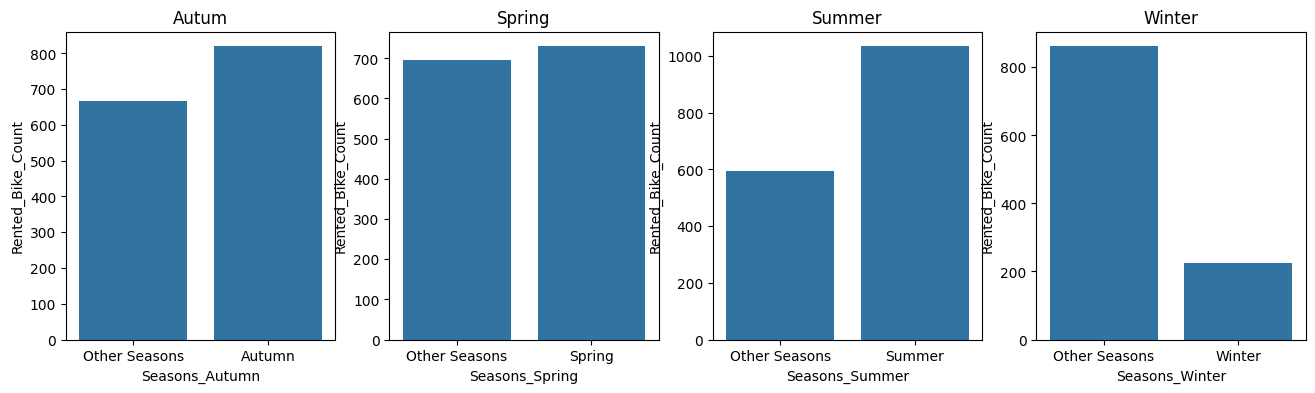

In [29]:
import matplotlib.pyplot as plt
import seaborn as sns 
fig, axes = plt.subplots(1, 4, figsize=(16, 4))
sns.barplot(data=cdf,x='Seasons_Autumn',y='Rented_Bike_Count',errorbar=None,ax=axes[0])
axes[0].set_title("Autum")
axes[0].set_xticklabels(['Other Seasons', 'Autumn'])

sns.barplot(data=cdf,x='Seasons_Spring',y='Rented_Bike_Count',errorbar=None,ax=axes[1])
axes[1].set_title("Spring")
axes[1].set_xticklabels(['Other Seasons', 'Spring'])

sns.barplot(data=cdf,x='Seasons_Summer',y='Rented_Bike_Count',errorbar=None,ax=axes[2])
axes[2].set_title("Summer")
axes[2].set_xticklabels(['Other Seasons', 'Summer'])

sns.barplot(data=cdf,x='Seasons_Winter',y='Rented_Bike_Count',errorbar=None,ax=axes[3])
axes[3].set_title("Winter")
plt.xticks([0, 1], ['Other Seasons', 'Winter'])

C:\Users\Pawan\AppData\Local\Temp\ipykernel_24212\1976011050.py:5: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  axes[0,0].set_xticklabels(['other seasons','Summer'])
C:\Users\Pawan\AppData\Local\Temp\ipykernel_24212\1976011050.py:8: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  axes[0,1].set_xticklabels(['other seasons','Winter'])
C:\Users\Pawan\AppData\Local\Temp\ipykernel_24212\1976011050.py:11: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  axes[1,0].set_xticklabels(['other seasons','Autumn'])
C:\Users\Pawan\AppData\Local\Temp\ipykernel_24212\1976011050.py:14: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  axes[1,1].set_xticklabels(['other seasons','Spri

[Text(0, 0, 'other seasons'), Text(1, 0, 'Spring')]

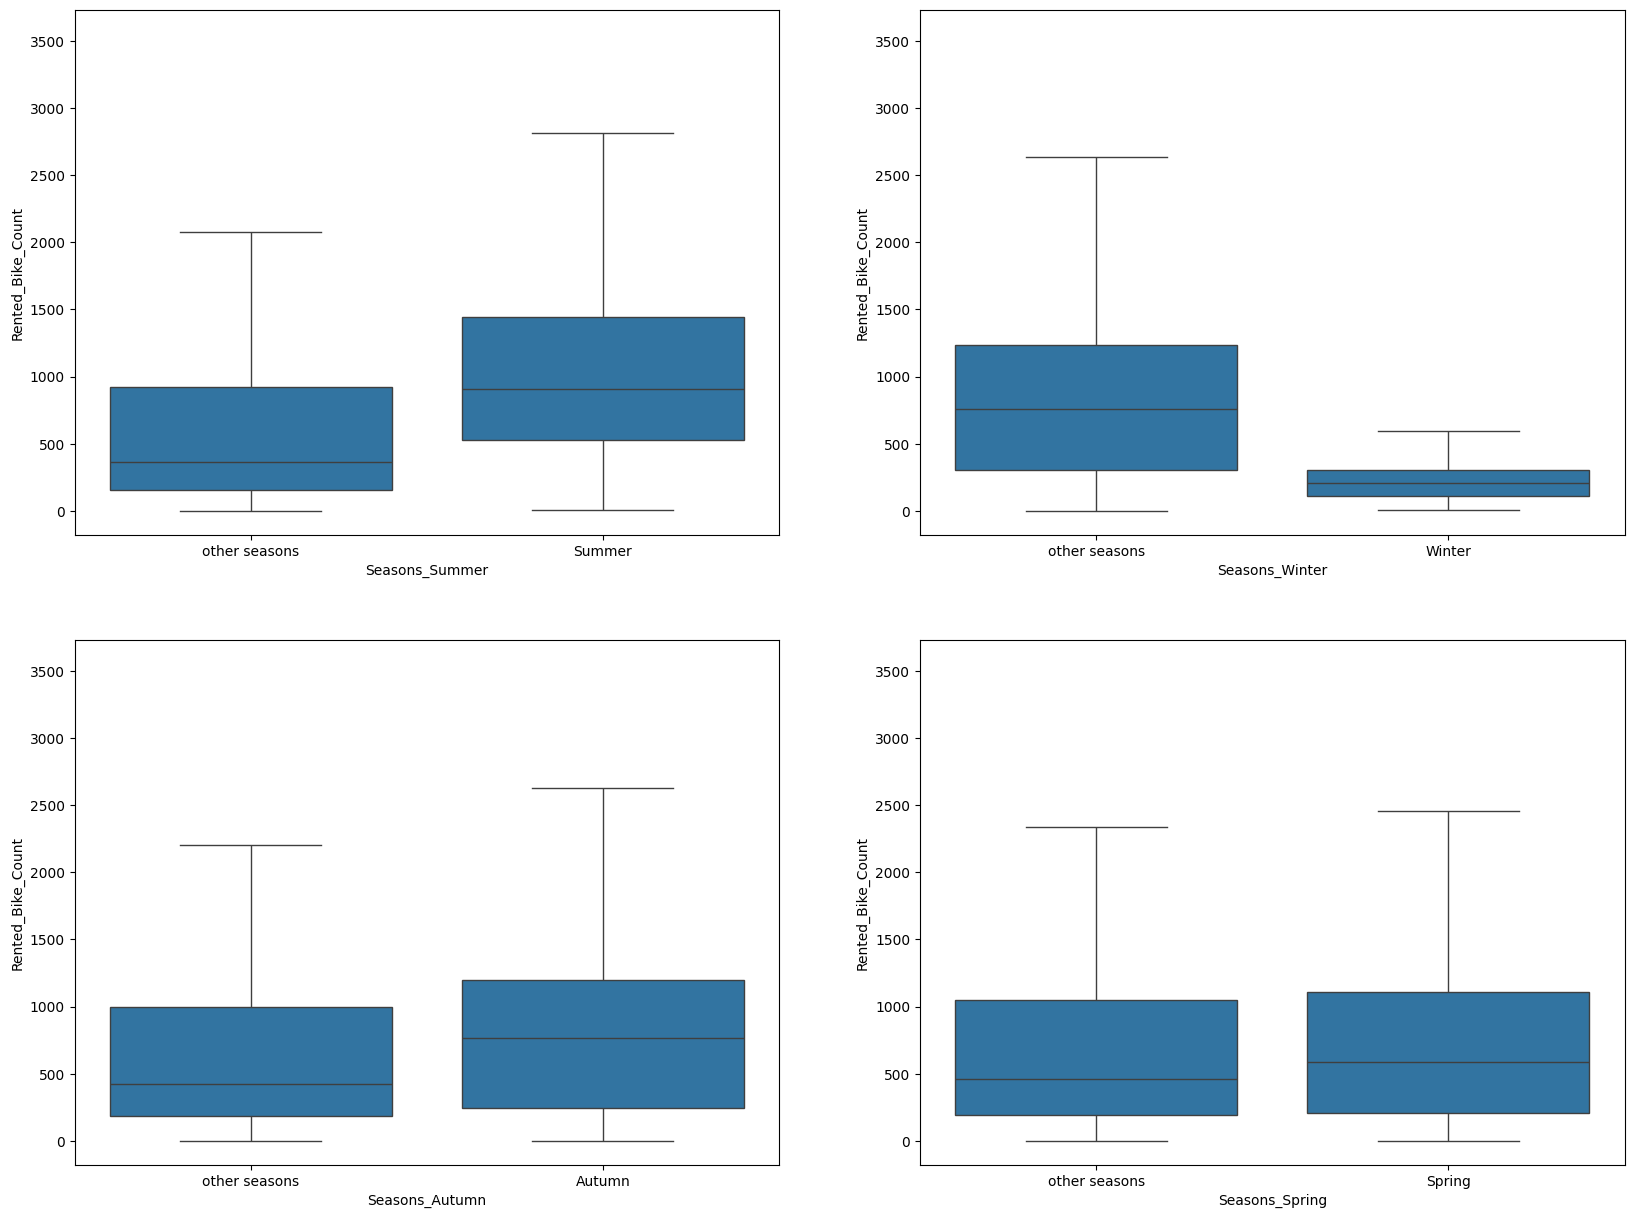

In [89]:
import seaborn as sns
import matplotlib.pyplot as plt
fig,axes=plt.subplots(2,2,figsize=(20,15))
sns.boxplot(data=cdf,x='Seasons_Summer',y='Rented_Bike_Count',fliersize=0,ax=axes[0,0])
axes[0,0].set_xticklabels(['other seasons','Summer'])

sns.boxplot(data=cdf,x='Seasons_Winter',y='Rented_Bike_Count',fliersize=0,ax=axes[0,1])
axes[0,1].set_xticklabels(['other seasons','Winter'])

sns.boxplot(data=cdf,x='Seasons_Autumn',y='Rented_Bike_Count',fliersize=0,ax=axes[1,0])
axes[1,0].set_xticklabels(['other seasons','Autumn'])

sns.boxplot(data=cdf,x='Seasons_Spring',y='Rented_Bike_Count',fliersize=0,ax=axes[1,1])
axes[1,1].set_xticklabels(['other seasons','Spring'])


<Axes: xlabel='Temperature', ylabel='Rented_Bike_Count'>

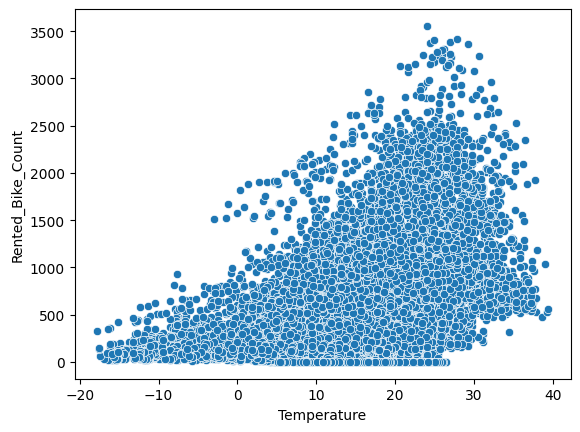

In [90]:
sns.scatterplot(data=cdf,x='Temperature',y='Rented_Bike_Count')

In [95]:
cdf.nunique()


Date                     365
Rented_Bike_Count       2166
Hour                      24
Temperature              546
Humidity                  90
Wind_Speed                65
Visibility              1789
DewPoint_temperature     556
Solar_Radiation          345
Rainfall                  61
Snowfall                  51
Holiday                    2
Functioning_Day            2
Seasons_Autumn             2
Seasons_Spring             2
Seasons_Summer             2
Seasons_Winter             2
Year                       2
Month                     12
Day                       31
DayOfWeek                  7
Is_Weekend                 2
dtype: int64

<Axes: xlabel='Rented_Bike_Count', ylabel='Count'>

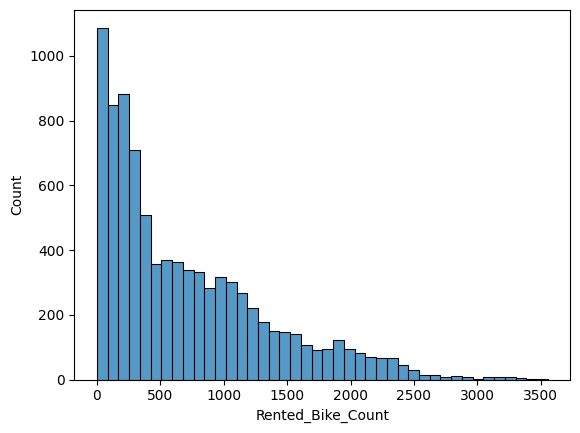

In [59]:
sns.histplot(data=cdf,x='Rented_Bike_Count')

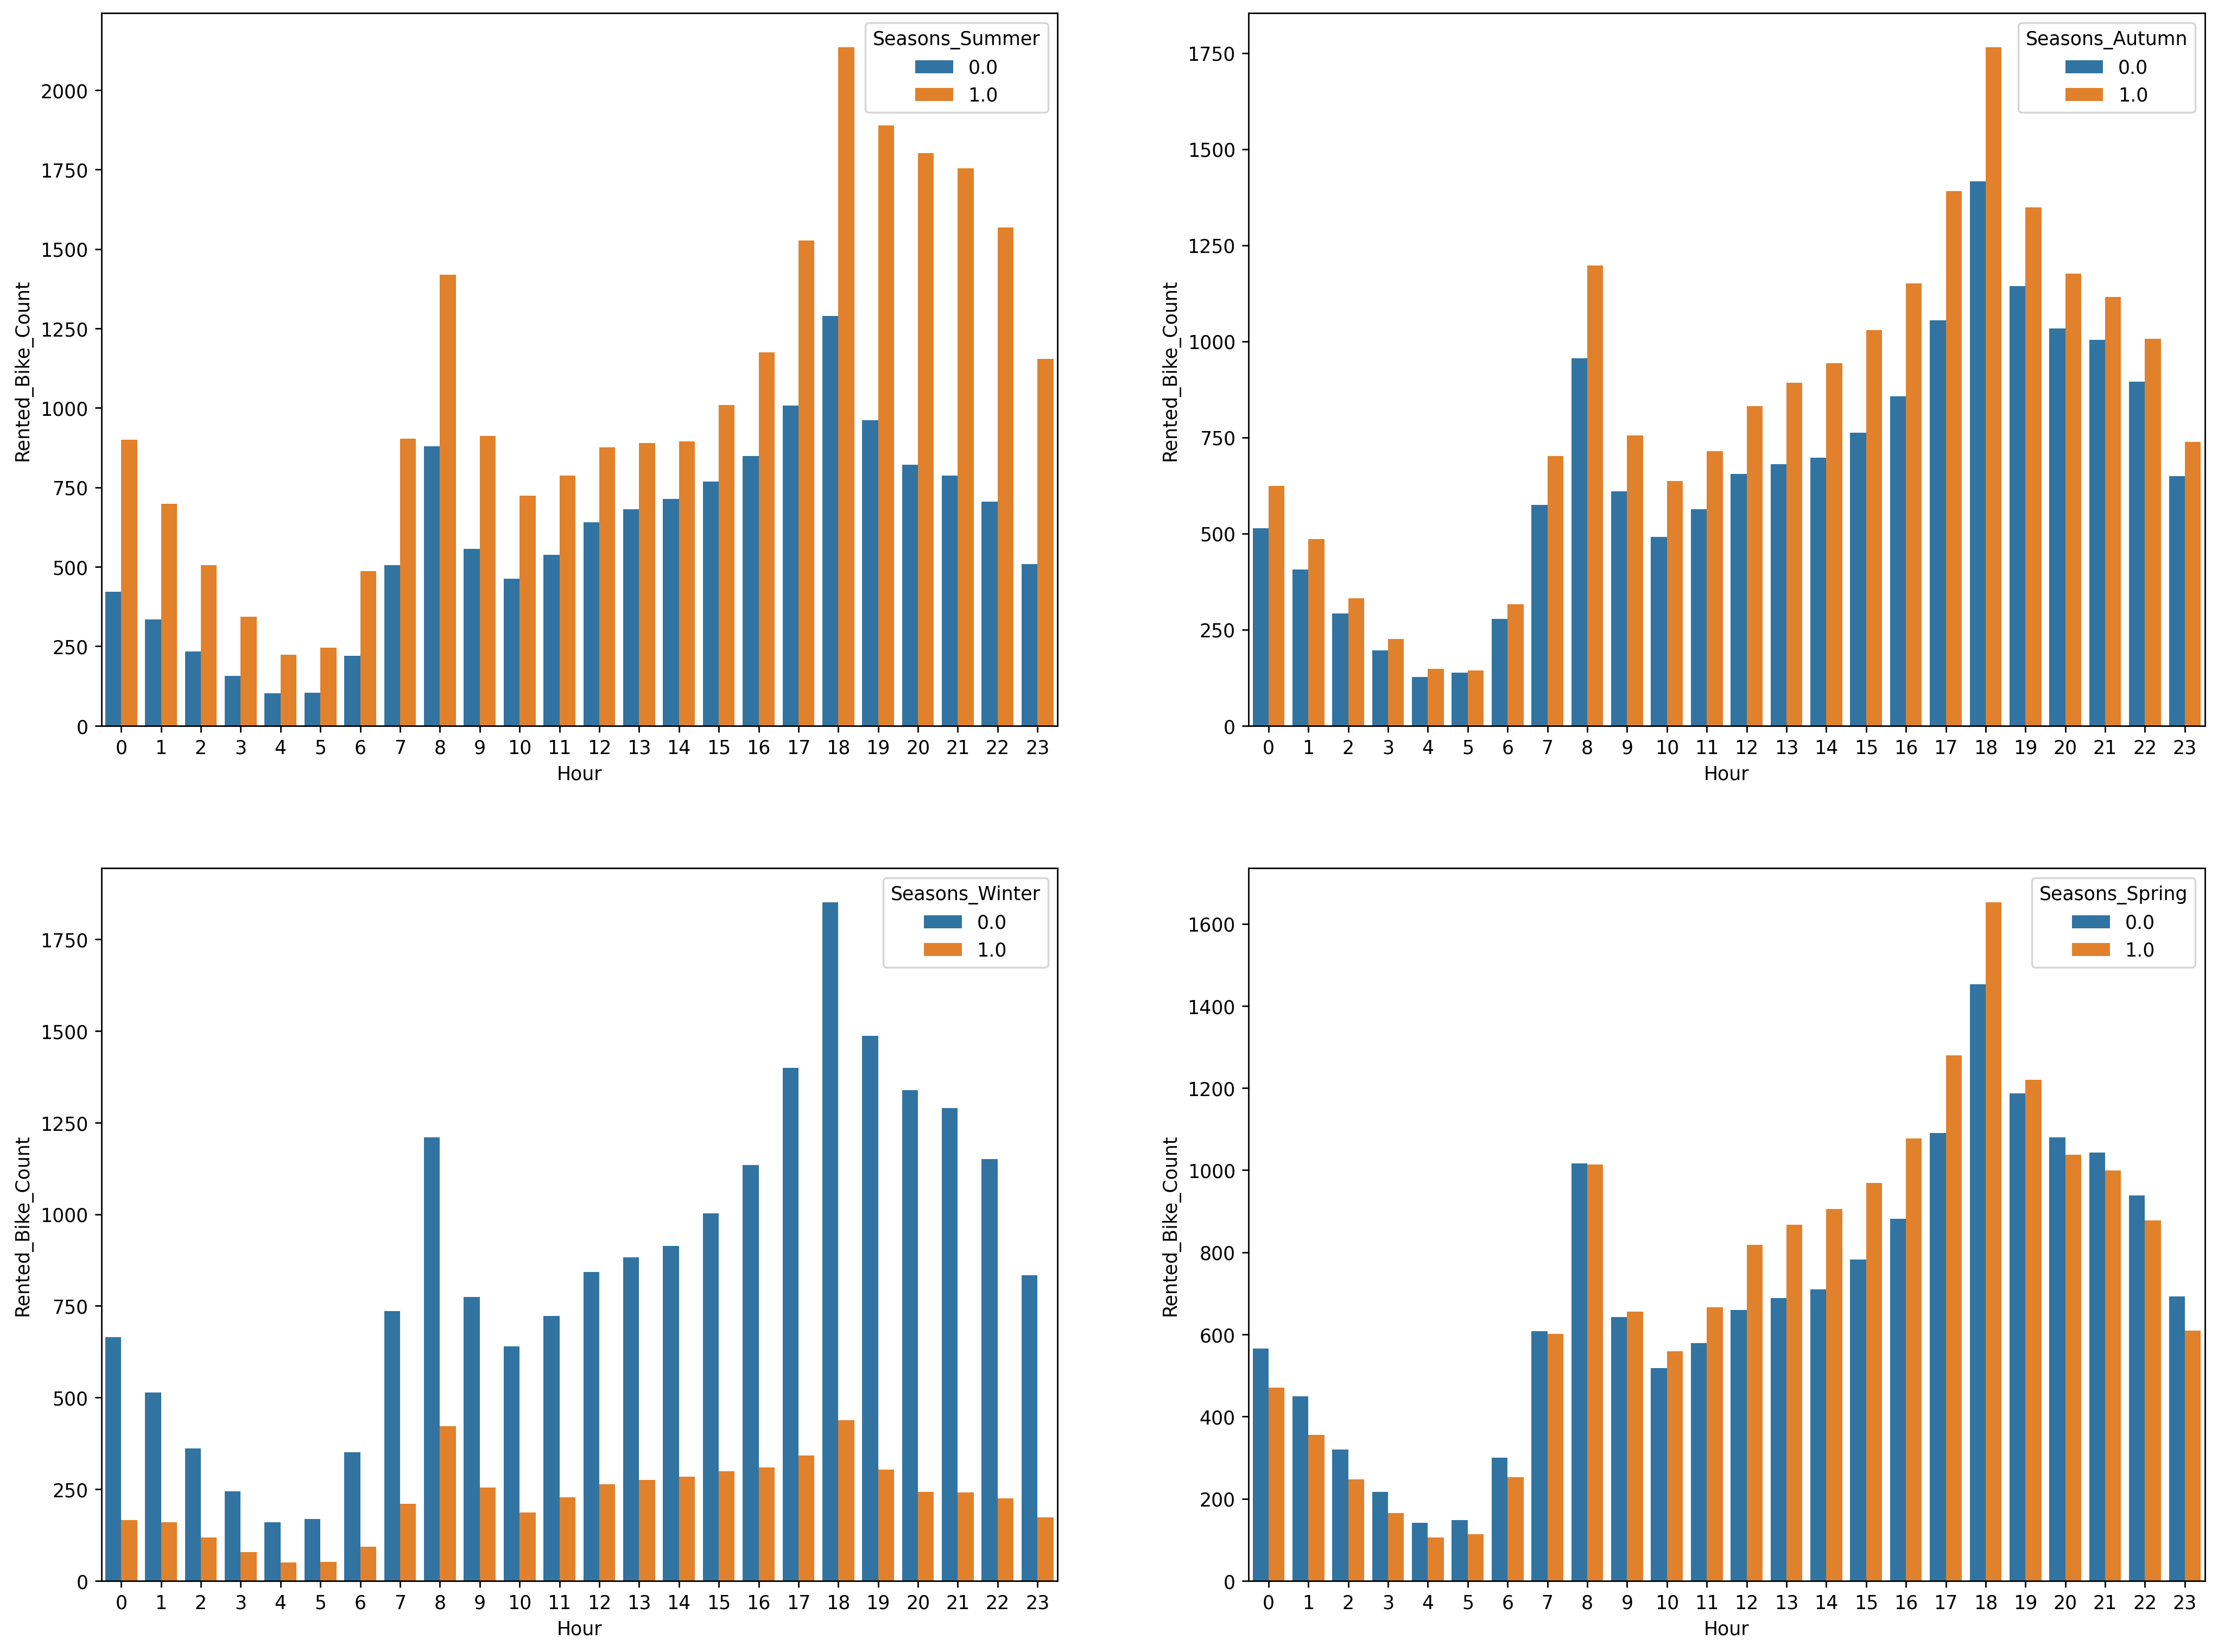

In [30]:
fig, axes = plt.subplots(2,2, figsize=(20,15),dpi=250)
sns.barplot(data=cdf,x='Hour',y='Rented_Bike_Count',errorbar=None,hue='Seasons_Summer',ax=axes[0,0])

sns.barplot(data=cdf,x='Hour',y='Rented_Bike_Count',errorbar=None,hue='Seasons_Autumn',ax=axes[0,1])

sns.barplot(data=cdf,x='Hour',y='Rented_Bike_Count',errorbar=None,hue='Seasons_Winter',ax=axes[1,0])

sns.barplot(data=cdf,x='Hour',y='Rented_Bike_Count',errorbar=None,hue='Seasons_Spring',ax=axes[1,1])


plt.show()

<Axes: xlabel='Visibility', ylabel='Rented_Bike_Count'>

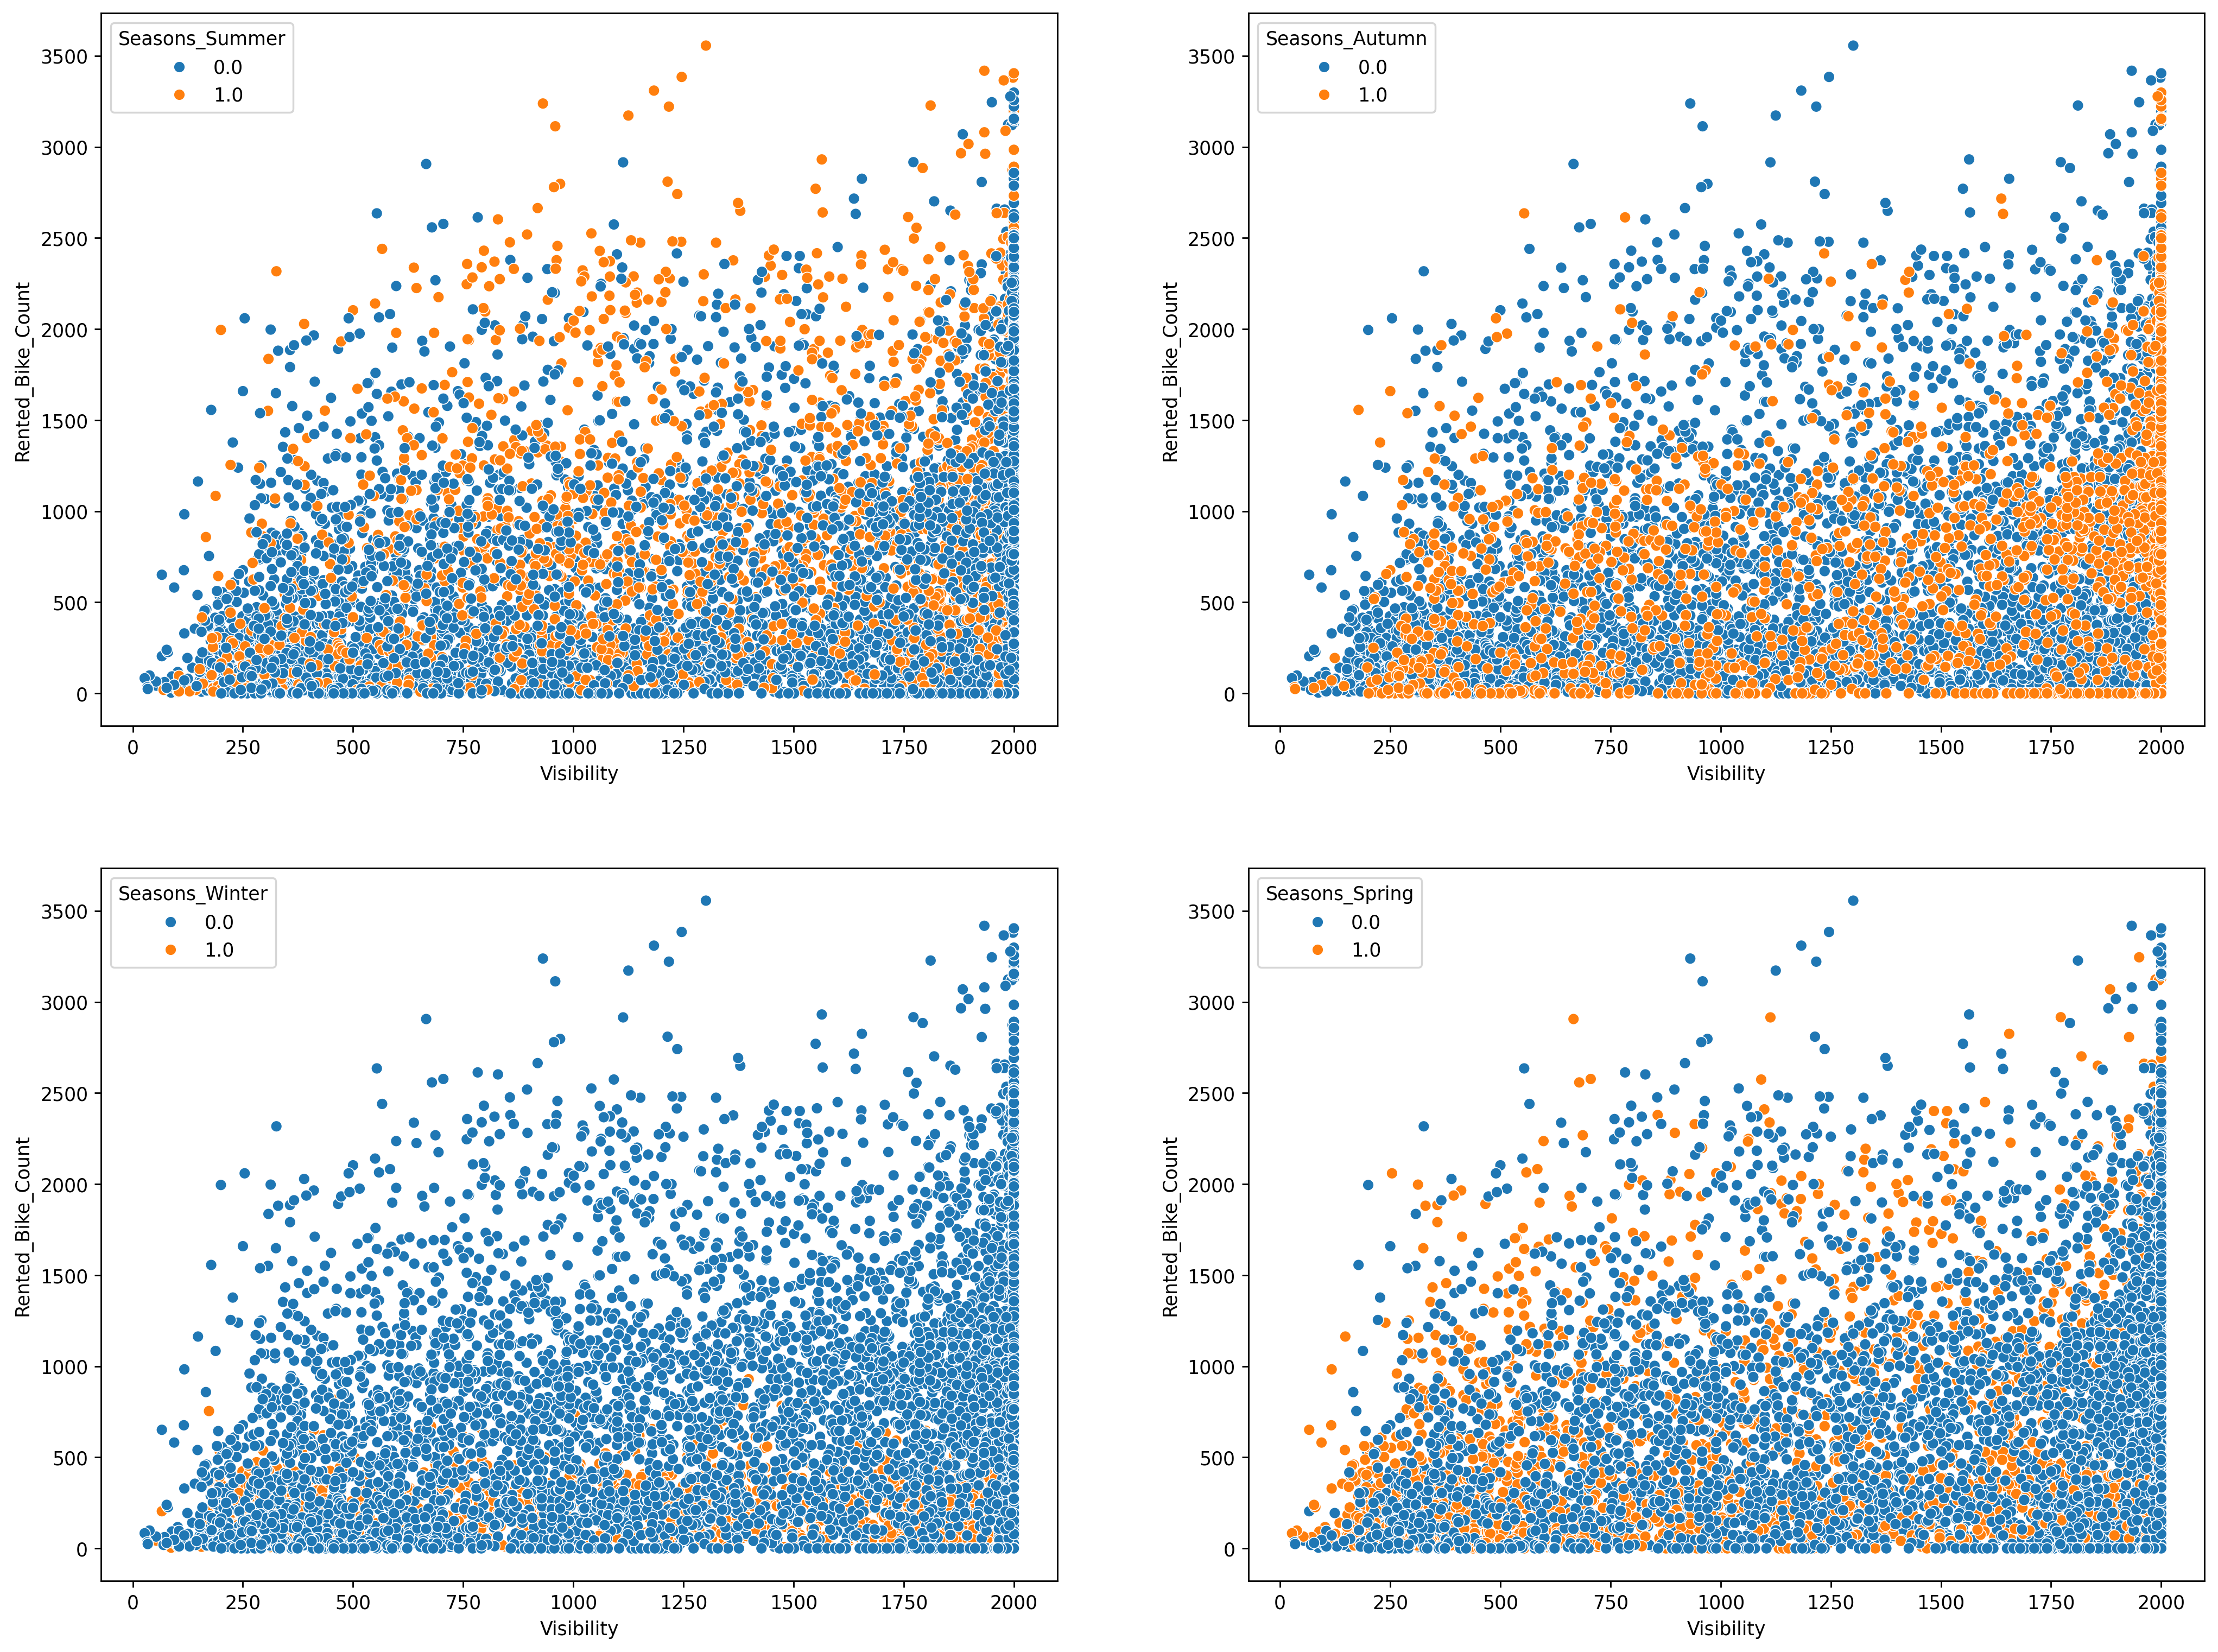

In [31]:
fig, axes = plt.subplots(2,2, figsize=(20,15),dpi=250)
sns.scatterplot(data=cdf,x='Visibility',y='Rented_Bike_Count',hue='Seasons_Summer',ax=axes[0,0])


sns.scatterplot(data=cdf,x='Visibility',y='Rented_Bike_Count',hue='Seasons_Autumn',ax=axes[0,1])


sns.scatterplot(data=cdf,x='Visibility',y='Rented_Bike_Count',hue='Seasons_Winter',ax=axes[1,0])


sns.scatterplot(data=cdf,x='Visibility',y='Rented_Bike_Count',hue='Seasons_Spring',ax=axes[1,1])



C:\Users\Pawan\AppData\Local\Temp\ipykernel_24212\1761370846.py:3: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  axes[0,0].set_xticklabels(['Other_Seasons','Winter'])
C:\Users\Pawan\AppData\Local\Temp\ipykernel_24212\1761370846.py:7: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  axes[0,1].set_xticklabels(['Other_Seasons','Spring'])
C:\Users\Pawan\AppData\Local\Temp\ipykernel_24212\1761370846.py:12: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  axes[1,1].set_xticklabels(['Other_Seasons','Summer'])
C:\Users\Pawan\AppData\Local\Temp\ipykernel_24212\1761370846.py:17: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  axes[1,0].set_xticklabels(['Other_Seasons','Autu

[Text(0, 0, 'Other_Seasons'), Text(1, 0, 'Autumn')]

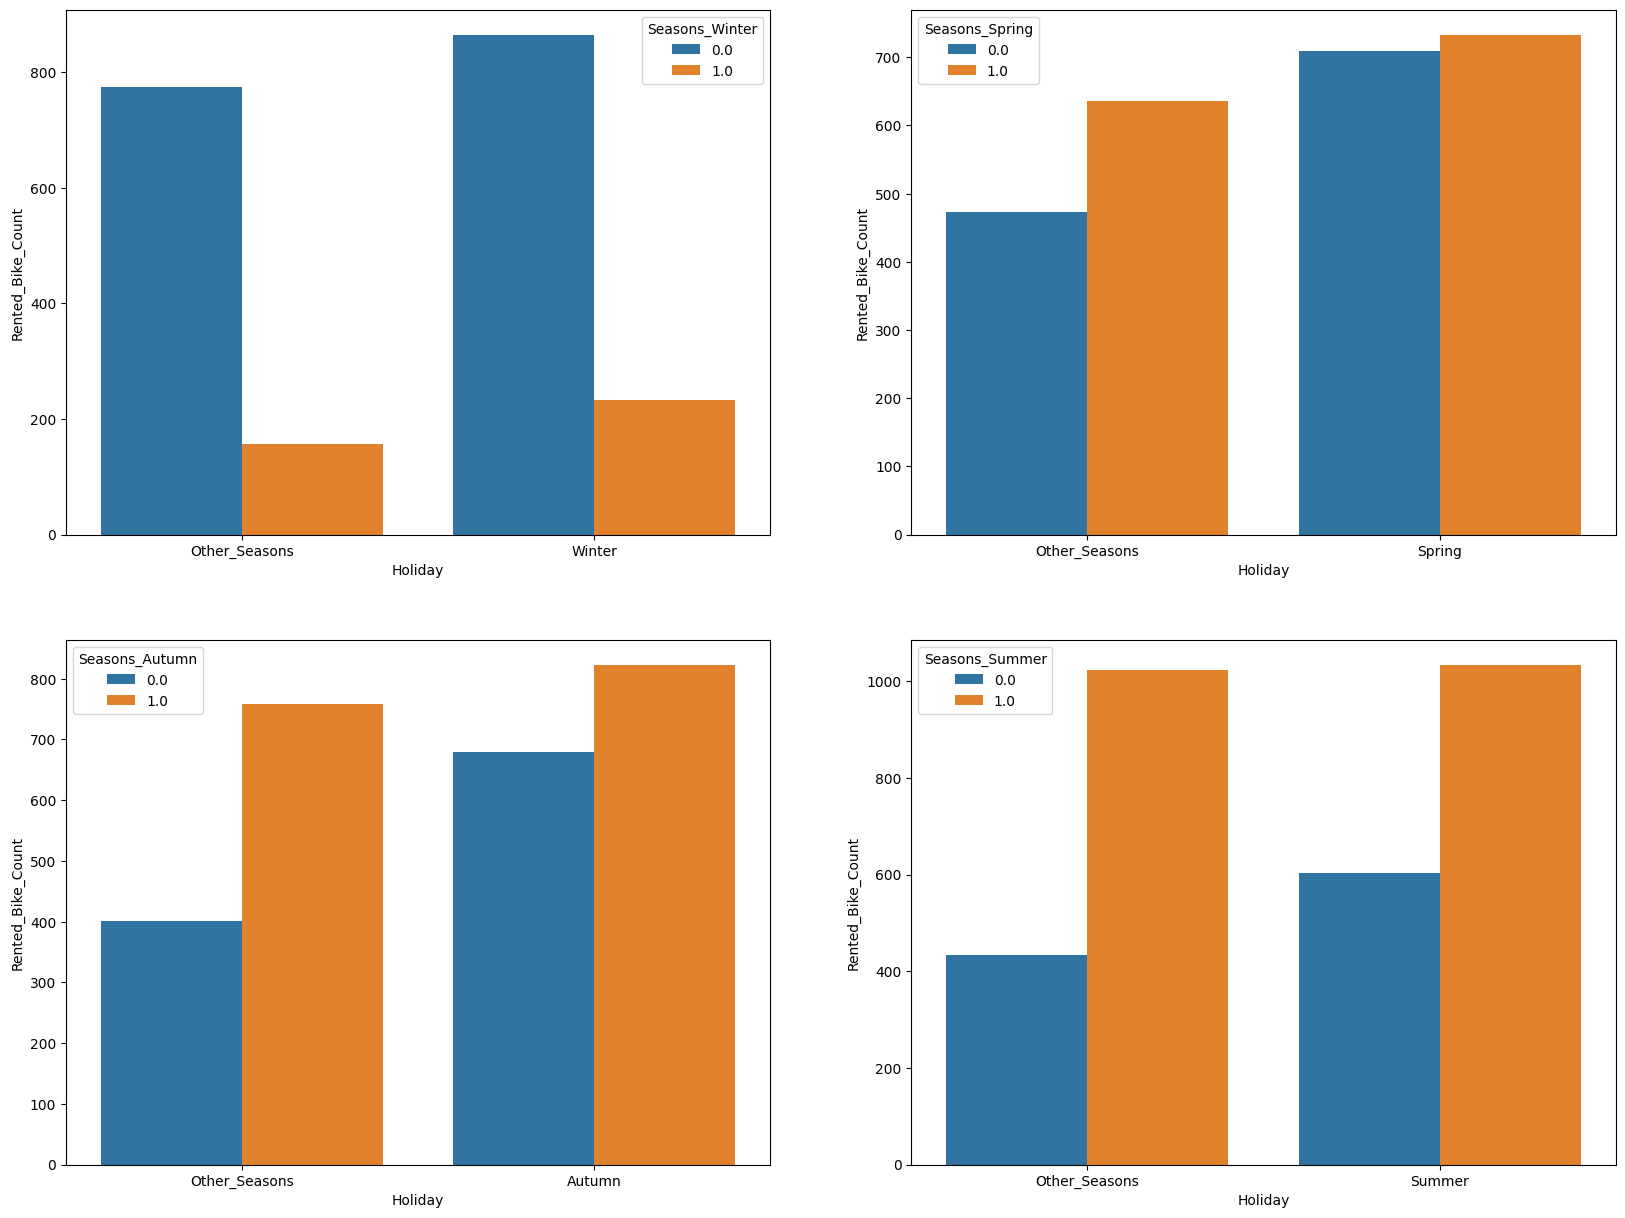

In [32]:
fig,axes=plt.subplots(2,2,figsize=(20,15))
sns.barplot(data=cdf,x='Holiday',y='Rented_Bike_Count',hue='Seasons_Winter',ax=axes[0,0],errorbar=None)
axes[0,0].set_xticklabels(['Other_Seasons','Winter'])


sns.barplot(data=cdf,x='Holiday',y='Rented_Bike_Count',hue='Seasons_Spring',ax=axes[0,1],errorbar=None)
axes[0,1].set_xticklabels(['Other_Seasons','Spring'])



sns.barplot(data=cdf,x='Holiday',y='Rented_Bike_Count',hue='Seasons_Summer',ax=axes[1,1],errorbar=None)
axes[1,1].set_xticklabels(['Other_Seasons','Summer'])



sns.barplot(data=cdf,x='Holiday',y='Rented_Bike_Count',hue='Seasons_Autumn',ax=axes[1,0],errorbar=None)
axes[1,0].set_xticklabels(['Other_Seasons','Autumn'])

Date	Rented_Bike_Count	Hour	Temperature	Humidity	Wind_Speed	Visibility	DewPoint_temperature	Solar_Radiation	Rainfall	...	Seasons_Autumn	Seasons_Spring	Seasons_Summer	Seasons_Winter	Year	Month	Summer	Autumn	Winter	Spring

In [33]:
cdf.head(0)

,Date,Rented_Bike_Count,Hour,Temperature,Humidity,Wind_Speed,Visibility,DewPoint_temperature,Solar_Radiation,Rainfall,Snowfall,Holiday,Functioning_Day,Seasons_Autumn,Seasons_Spring,Seasons_Summer,Seasons_Winter,Year,Month


In [34]:
cdf

,Date,Rented_Bike_Count,Hour,Temperature,Humidity,Wind_Speed,Visibility,DewPoint_temperature,Solar_Radiation,Rainfall,Snowfall,Holiday,Functioning_Day,Seasons_Autumn,Seasons_Spring,Seasons_Summer,Seasons_Winter,Year,Month
0,2017-01-12,254,0,-5.2,37,2.2,2000,-17.6,0.0,0.0,0.0,1,1,0.0,0.0,0.0,1.0,2017,1
1,2017-01-12,204,1,-5.5,38,0.8,2000,-17.6,0.0,0.0,0.0,1,1,0.0,0.0,0.0,1.0,2017,1
2,2017-01-12,173,2,-6.0,39,1.0,2000,-17.7,0.0,0.0,0.0,1,1,0.0,0.0,0.0,1.0,2017,1
3,2017-01-12,107,3,-6.2,40,0.9,2000,-17.6,0.0,0.0,0.0,1,1,0.0,0.0,0.0,1.0,2017,1
4,2017-01-12,78,4,-6.0,36,2.3,2000,-18.6,0.0,0.0,0.0,1,1,0.0,0.0,0.0,1.0,2017,1
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
8755,2018-11-30,1003,19,4.2,34,2.6,1894,-10.3,0.0,0.0,0.0,1,1,1.0,0.0,0.0,0.0,2018,11
8756,2018-11-30,764,20,3.4,37,2.3,2000,-9.9,0.0,0.0,0.0,1,1,1.0,0.0,0.0,0.0,2018,11
8757,2018-11-30,694,21,2.6,39,0.3,1968,-9.9,0.0,0.0,0.0,1,1,1.0,0.0,0.0,0.0,2018,11
8758,2018-11-30,712,22,2.1,41,1.0,1859,-9.8,0.0,0.0,0.0,1,1,1.0,0.0,0.0,0.0,2018,11


In [35]:
correlation=cdf.corr(numeric_only=True)
correlation['Rented_Bike_Count'].sort_values(ascending=False)

Rented_Bike_Count       1.000000
Temperature             0.538558
Hour                    0.410257
DewPoint_temperature    0.379788
Seasons_Summer          0.296549
Solar_Radiation         0.261837
Year                    0.215162
Functioning_Day         0.203943
Visibility              0.199280
Wind_Speed              0.121108
Seasons_Autumn          0.102753
Holiday                 0.072338
Month                   0.070861
Seasons_Spring          0.022888
Rainfall               -0.123074
Snowfall               -0.141804
Humidity               -0.199780
Seasons_Winter         -0.424925
Name: Rented_Bike_Count, dtype: float64

In [36]:
cdf['Day'] = cdf['Date'].dt.day
cdf['DayOfWeek'] = cdf['Date'].dt.dayofweek
cdf['Is_Weekend'] = (cdf['DayOfWeek'] >= 5).astype(int)

In [37]:
cdf

,Date,Rented_Bike_Count,Hour,Temperature,Humidity,Wind_Speed,Visibility,DewPoint_temperature,Solar_Radiation,Rainfall,...,Functioning_Day,Seasons_Autumn,Seasons_Spring,Seasons_Summer,Seasons_Winter,Year,Month,Day,DayOfWeek,Is_Weekend
0,2017-01-12,254,0,-5.2,37,2.2,2000,-17.6,0.0,0.0,...,1,0.0,0.0,0.0,1.0,2017,1,12,3,0
1,2017-01-12,204,1,-5.5,38,0.8,2000,-17.6,0.0,0.0,...,1,0.0,0.0,0.0,1.0,2017,1,12,3,0
2,2017-01-12,173,2,-6.0,39,1.0,2000,-17.7,0.0,0.0,...,1,0.0,0.0,0.0,1.0,2017,1,12,3,0
3,2017-01-12,107,3,-6.2,40,0.9,2000,-17.6,0.0,0.0,...,1,0.0,0.0,0.0,1.0,2017,1,12,3,0
4,2017-01-12,78,4,-6.0,36,2.3,2000,-18.6,0.0,0.0,...,1,0.0,0.0,0.0,1.0,2017,1,12,3,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
8755,2018-11-30,1003,19,4.2,34,2.6,1894,-10.3,0.0,0.0,...,1,1.0,0.0,0.0,0.0,2018,11,30,4,0
8756,2018-11-30,764,20,3.4,37,2.3,2000,-9.9,0.0,0.0,...,1,1.0,0.0,0.0,0.0,2018,11,30,4,0
8757,2018-11-30,694,21,2.6,39,0.3,1968,-9.9,0.0,0.0,...,1,1.0,0.0,0.0,0.0,2018,11,30,4,0
8758,2018-11-30,712,22,2.1,41,1.0,1859,-9.8,0.0,0.0,...,1,1.0,0.0,0.0,0.0,2018,11,30,4,0


In [38]:
X=cdf.drop(['Date','Rented_Bike_Count','Seasons_Winter'],axis=1)
Y=cdf['Rented_Bike_Count']

In [39]:
from sklearn.model_selection import train_test_split 
from sklearn.linear_model import LinearRegression
from sklearn.preprocessing import StandardScaler

x_train,x_test,y_train,y_test=train_test_split(X,Y,test_size=0.20,random_state=42)
scalaer=StandardScaler()
x_train_scaled=scalaer.fit_transform(x_train)
x_test_scaled=scalaer.transform(x_test)

model=LinearRegression()

model.fit(x_train_scaled,y_train)

,fit_intercept,True
,copy_X,True
,tol,1e-06
,n_jobs,None
,positive,False


In [40]:
y_pred=model.predict(x_test_scaled)

In [41]:
from sklearn.metrics import r2_score,mean_absolute_error,mean_squared_error,accuracy_score,classification_report
print('r2 :',r2_score(y_test,y_pred))
print("MAE :",mean_absolute_error(y_test,y_pred))
print('MSE :',mean_squared_error(y_test,y_pred))
print("RMSE :",mean_squared_error(y_test,y_pred)**0.5)

r2 : 0.535439771114363
MAE : 330.5311486383008
MSE : 193557.2715541713
RMSE : 439.9514422685432


***KNN REGRESSOR***

In [42]:
from sklearn.neighbors import KNeighborsRegressor

knn=KNeighborsRegressor(n_neighbors=1)

knn.fit(x_train_scaled,y_train)


,n_neighbors,1
,weights,'uniform'
,algorithm,'auto'
,leaf_size,30
,p,2
,metric,'minkowski'
,metric_params,None
,n_jobs,None


In [43]:
y_pred_knn_reg=knn.predict(x_test_scaled)

In [44]:
from sklearn.metrics import r2_score,mean_absolute_error,mean_squared_error,accuracy_score,classification_report,root_mean_squared_error
print('Accuracy :',r2_score(y_test,y_pred_knn_reg))
print('Classification report ')
print('mean_absolute_error',mean_absolute_error(y_test,y_pred_knn_reg))
print('mean_squared_error',mean_squared_error(y_test,y_pred_knn_reg))
print('RMSE :',root_mean_squared_error(y_test,y_pred_knn_reg))


Accuracy : 0.7229306428252821
Classification report 
mean_absolute_error 210.61529680365297
mean_squared_error 115439.90525114155
RMSE : 339.7644849761987


***Using grid Search Cv***

In [45]:
from sklearn.model_selection import GridSearchCV
from sklearn.pipeline import Pipeline

def knn_reg(neighbor):
    return Pipeline([
        ('scalaer',StandardScaler()),
        ('knn',KNeighborsRegressor())
    ])
mods=knn_reg(neighbor=1)

param_grid={
    'knn__n_neighbors':list(range(1,15))
}

grid=GridSearchCV(
    estimator=mods,
    cv=5,
    param_grid=param_grid,
    scoring='r2'
)

grid.fit(x_train,y_train)

,estimator,Pipeline(step...Regressor())])
,param_grid,"{'knn__n_neighbors': [1, 2, ...]}"
,scoring,'r2'
,n_jobs,None
,refit,True
,cv,5
,verbose,0
,pre_dispatch,'2*n_jobs'
,error_score,nan
,return_train_score,False
,copy,True


In [46]:
print("Best Estimator :",grid.best_estimator_)
print('Best_Score :',grid.best_score_)
print('Best_Param :',grid.best_params_)


Best Estimator : Pipeline(steps=[('scalaer', StandardScaler()),
                ('knn', KNeighborsRegressor(n_neighbors=4))])
Best_Score : 0.7600068387038384
Best_Param : {'knn__n_neighbors': 4}


***Decison Tree Regressor***

In [47]:
from sklearn.tree import DecisionTreeRegressor
tree=DecisionTreeRegressor(max_depth=1)

tree.fit(x_train,y_train)

,criterion,'squared_error'
,splitter,'best'
,max_depth,1
,min_samples_split,2
,min_samples_leaf,1
,min_weight_fraction_leaf,0.0
,max_features,None
,random_state,None
,max_leaf_nodes,None
,min_impurity_decrease,0.0
,ccp_alpha,0.0


In [48]:
tree_y_pred=tree.predict(x_test)

In [49]:
print("r2_score :", r2_score(y_test,tree_y_pred))
print('mean_absolute_error',mean_absolute_error(y_test,tree_y_pred))
print('mean_squared_error',mean_squared_error(y_test,tree_y_pred))
print('root_mean_squared_error',root_mean_squared_error(y_test,tree_y_pred))

r2_score : 0.23992026706824765
mean_absolute_error 420.3417808037613
mean_squared_error 316684.3610844487
root_mean_squared_error 562.747155554294


In [50]:
from sklearn.model_selection import GridSearchCV
from sklearn.pipeline import Pipeline

def D_reg(depth):
    return Pipeline([
        ('Decision',DecisionTreeRegressor(max_depth=depth))
    ])
mods=D_reg(depth=1)

param_grid={
    'Decision__max_depth':list(range(1,15))
}

grid=GridSearchCV(
    estimator=mods,
    cv=5,
    param_grid=param_grid,
    scoring='r2'
)

grid.fit(x_train,y_train)

,estimator,Pipeline(step...ax_depth=1))])
,param_grid,"{'Decision__max_depth': [1, 2, ...]}"
,scoring,'r2'
,n_jobs,None
,refit,True
,cv,5
,verbose,0
,pre_dispatch,'2*n_jobs'
,error_score,nan
,return_train_score,False
,criterion,'squared_error'


In [51]:
print("Best Estimator :",grid.best_estimator_)
print('Best_Score :',grid.best_score_)
print('Best_Param :',grid.best_params_)


Best Estimator : Pipeline(steps=[('Decision', DecisionTreeRegressor(max_depth=10))])
Best_Score : 0.8179962223944921
Best_Param : {'Decision__max_depth': 10}


***RANDOM FOREST***

In [52]:
from sklearn.ensemble import RandomForestRegressor

models=RandomForestRegressor(max_depth=1)

models.fit(x_train,y_train)

,n_estimators,100
,criterion,'squared_error'
,max_depth,1
,min_samples_split,2
,min_samples_leaf,1
,min_weight_fraction_leaf,0.0
,max_features,1.0
,max_leaf_nodes,None
,min_impurity_decrease,0.0
,bootstrap,True
,oob_score,False


In [53]:
RF_y_pred=models.predict(x_test)

In [54]:
from sklearn.metrics import f1_score
print("r2_score :", r2_score(y_test,RF_y_pred))
print('mean_absolute_error',mean_absolute_error(y_test,RF_y_pred))
print('mean_squared_error',mean_squared_error(y_test,RF_y_pred))
print('root_mean_squared_error',root_mean_squared_error(y_test,RF_y_pred))


r2_score : 0.2511463269168006
mean_absolute_error 417.5132377020136
mean_squared_error 312007.06548425934
root_mean_squared_error 558.5759263379146


***Random Forest Using grid Search Cv***

In [55]:
from sklearn.model_selection import GridSearchCV
from sklearn.pipeline import Pipeline
from sklearn.ensemble import RandomForestRegressor

def RF_reg(depth):
    return Pipeline([
        ('RF',RandomForestRegressor(max_depth=depth))
    ])
mods=RF_reg(depth=1)

param_grid={
    'RF__max_depth':list(range(1,10)),
    'RF__n_estimators':[100,150,None],
}

grid=GridSearchCV(
    estimator=mods,
    cv=3,
    param_grid=param_grid,
    scoring='r2'
)

grid.fit(x_train,y_train)

c:\Users\Pawan\AppData\Local\Programs\Python\Python313\Lib\site-packages\sklearn\model_selection\_validation.py:516: FitFailedWarning: 
27 fits failed out of a total of 81.
The score on these train-test partitions for these parameters will be set to nan.
If these failures are not expected, you can try to debug them by setting error_score='raise'.

Below are more details about the failures:
--------------------------------------------------------------------------------
27 fits failed with the following error:
Traceback (most recent call last):
  File "c:\Users\Pawan\AppData\Local\Programs\Python\Python313\Lib\site-packages\sklearn\model_selection\_validation.py", line 859, in _fit_and_score
    estimator.fit(X_train, y_train, **fit_params)
    ~~~~~~~~~~~~~^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^
  File "c:\Users\Pawan\AppData\Local\Programs\Python\Python313\Lib\site-packages\sklearn\base.py", line 1365, in wrapper
    return fit_method(estimator, *args, **kwargs)
  File "c:\Users\Pawan\AppDat

,estimator,Pipeline(step...ax_depth=1))])
,param_grid,"{'RF__max_depth': [1, 2, ...], 'RF__n_estimators': [100, 150, ...]}"
,scoring,'r2'
,n_jobs,None
,refit,True
,cv,3
,verbose,0
,pre_dispatch,'2*n_jobs'
,error_score,nan
,return_train_score,False
,n_estimators,100


In [56]:
print("Best Estimator :",grid.best_estimator_)
print('Best_Score :',grid.best_score_)
print('Best_Param :',grid.best_params_)

Best Estimator : Pipeline(steps=[('RF', RandomForestRegressor(max_depth=9))])
Best_Score : 0.8607463875090954
Best_Param : {'RF__max_depth': 9, 'RF__n_estimators': 100}


In [57]:
RF_y_grid_pred=grid.best_estimator_.predict(x_test)

In [58]:
print("r2_score :", r2_score(y_test,RF_y_grid_pred))
print('mean_absolute_error',mean_absolute_error(y_test,RF_y_grid_pred))
print('mean_squared_error',mean_squared_error(y_test,RF_y_grid_pred))
print('root_mean_squared_error',root_mean_squared_error(y_test,RF_y_grid_pred))

r2_score : 0.8586051017262734
mean_absolute_error 148.60738647667415
mean_squared_error 58911.65239691548
root_mean_squared_error 242.71722723555385
